# Cost setting

Minimize the cumulative cost
$\mathcal{R}_{t_F}=(\Delta\,\mathcal{Q}+\mathcal{M})/d$, where $\mathcal{Q}$ is
the number of queries and $\mathcal{M}$ the number of unqueried mistakes over the
whole stream of $n=t_F d$ samples. Each query costs $\Delta$ and each unqueried
mistake costs $1$. No budget constraint.

Set `RECOMPUTE = True` to redo the optimization and the simulations from
scratch (about 14 min).

In [1]:
import os, numpy as np, matplotlib.pyplot as plt
import adatron as A, optimize as O, plotting as P

RECOMPUTE = False
p = A.Params()
DELTAS = np.array([0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45])
D = 1000
os.makedirs('results', exist_ok=True)
os.makedirs('figures', exist_ok=True)
p

Params(eta=0.5, m0=0.0, q0=0.15, t_F=20.0, n_steps=2000)

## Optimal policies

In [2]:
if RECOMPUTE or not os.path.exists('results/cost.npz'):
    np.savez('results/cost.npz', **O.sweep_cost(p, DELTAS))
ode = dict(np.load('results/cost.npz'))

print('intermediate-margin schedule: inner radius a*_t = 0 at every price'
      ' (max %.1g)' % ode['a_sched'].max())
dear = ode['deltas'][ode['a_const'] > 1e-6]
print('constant intermediate margin: a* > 0 only at Delta =',
      np.round(dear, 2) if len(dear) else 'no price')
print()
print(' Delta  ' + '  '.join('%8s' % k for k in O.KEYS))
for i, d in enumerate(ode['deltas']):
    print('%6.2f  ' % d + '  '.join('%8.3f' % ode['R_' + k][i] for k in O.KEYS))

intermediate-margin schedule: inner radius a*_t = 0 at every price (max 0)
constant intermediate margin: a* > 0 only at Delta = [0.45]

 Delta     local      cmar      smar      cann      sann      rand
  0.05     0.838     1.000     0.836     1.000     0.836     1.000
  0.10     1.621     2.000     1.601     2.000     1.601     2.000
  0.15     2.391     3.000     2.328     3.000     2.328     3.000
  0.20     3.168     4.000     3.025     4.000     3.025     4.000
  0.25     3.969     4.897     3.695     4.897     3.695     4.986
  0.30     4.811     5.682     4.339     5.682     4.339     5.830
  0.35     5.718     6.414     4.956     6.414     4.956     6.538
  0.40     6.733     7.106     5.542     7.106     5.542     7.141
  0.45     7.946     7.764     6.090     7.583     6.090     7.659


## Finite-$d$ SGD simulations

One run per point at $d=1000$, as in the budget setting.

In [3]:
def sim_cost():
    cost = {k: np.zeros(len(DELTAS)) for k in O.KEYS}
    for i, d in enumerate(DELTAS):
        d = float(d)
        policies = {
            'local': A.LocalCost(d),
            'cmar':  A.Margin(float(ode['kappa'][i])),
            'smar':  A.MarginSchedule(ode['kap_sched'][i], p.t_F),
            'cann':  A.Annulus(float(ode['a_const'][i]), float(ode['b_const'][i])),
            'sann':  A.Schedule(ode['a_sched'][i], ode['b_sched'][i], p.t_F),
            'rand':  A.Random(float(ode['p_rand'][i]))}
        for k in O.KEYS:
            cost[k][i] = A.simulate(policies[k], p, d=D, seed=200 + i,
                                    delta=d)['R'][0]
        print('Delta=%.2f done' % d, flush=True)
    out = {'deltas': DELTAS}
    out.update({'C_' + k: cost[k] for k in O.KEYS})
    return out

if RECOMPUTE or not os.path.exists('results/sim_cost.npz'):
    np.savez('results/sim_cost.npz', **sim_cost())
sim = dict(np.load('results/sim_cost.npz'))
print('max |ODE - SGD| = %.4f' % max(np.abs(ode['R_'+k]-sim['C_'+k]).max()
                                     for k in O.KEYS))

max |ODE - SGD| = 0.1513


## Figure: cumulative cost versus query price

Where a family coincides with the smaller one it contains, it is drawn as a
translucent band behind it. The constant intermediate margin does so at every
price but the largest, where a positive inner radius starts to pay and the band
separates.

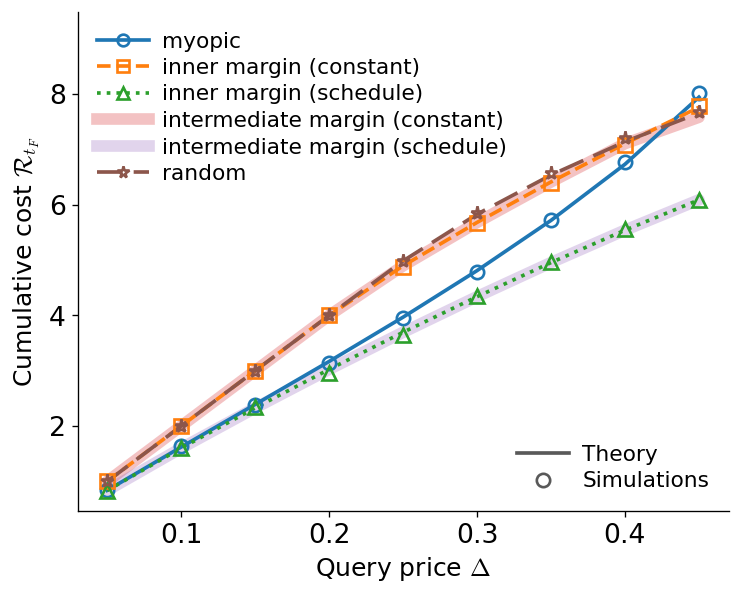

In [4]:
# a family that lies under the one it contains at most prices is drawn as a
# thick translucent band, so a hidden curve is not read as missing data
NESTED = {'cann': 'cmar', 'sann': 'smar'}
halo = tuple(k for k, inner in NESTED.items()
             if np.mean(np.isclose(ode['R_' + k], ode['R_' + inner])) > 0.5)

fig, ax = P.curve_figure(ode['deltas'], ode, sim, 'R_', 'C_',
                         r'Query price $\Delta$',
                         r'Cumulative cost $\mathcal{R}_{t_F}$',
                         loc='upper left', halo=halo, labelsize=15)
fig.savefig('figures/fig_cost.pdf')

## Figure: selection map at one price

Both sets are inner margins, with no central hole: under this objective a query
also buys the avoidance of an immediate mistake, and that benefit is largest at
the decision boundary. The horizon-optimized schedule queries a wider margin
early, paying for labels that are not yet worth their immediate price.

The horizon-optimized policy here is optimized over *both* radii of an
intermediate margin $a_t<|\omega|<b_t$. That the inner radius comes back at
zero is therefore an outcome of the search, not something imposed.

optimizing over both radii gives an inner edge of at most 0.00e+00


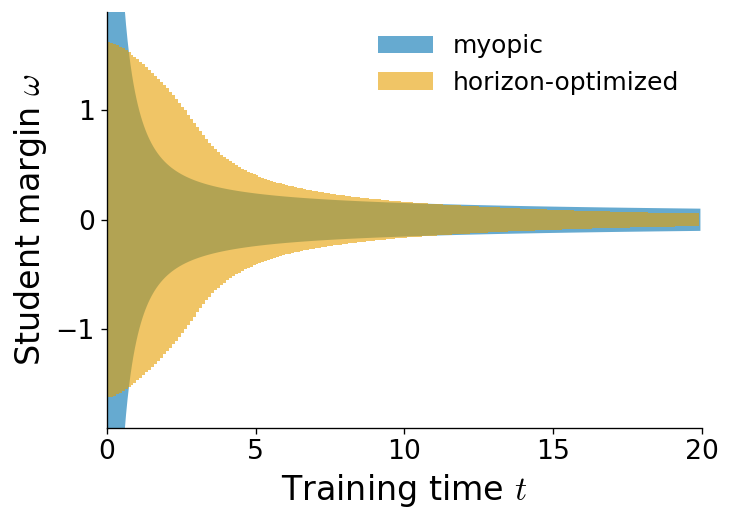

In [5]:
DEL = 0.3
i = int(np.argmin(np.abs(ode['deltas'] - DEL)))

# the horizon-optimized policy is searched over both radii (a_t, b_t) of an
# intermediate margin, not only over an inner margin, so that its collapse to
# a_t = 0 is a result of the optimization rather than an assumption
if RECOMPUTE or not os.path.exists('results/selmap_cost.npz'):
    kap_loc = O.local_cost_kappa(p, DEL, n=400)
    a_fine, b_fine = O.refine_schedule(p, ode['a_sched'][i], ode['b_sched'][i],
                                       'cost', delta=DEL)
    np.savez('results/selmap_cost.npz', kap_loc=kap_loc, a_fine=a_fine,
             b_fine=b_fine)
S = dict(np.load('results/selmap_cost.npz'))
print('optimizing over both radii gives an inner edge of at most %.2e'
      % S['a_fine'].max())

t_loc  = (p.t_F / len(S['kap_loc'])) * np.arange(len(S['kap_loc']))
t_fine = (p.t_F / len(S['a_fine'])) * np.arange(len(S['a_fine']))
fig, ax = P.selection_overlay(
    P.Band(t_loc,  -S['kap_loc'], S['kap_loc'], step=False, mirror=False),
    P.Band(t_fine, S['a_fine'],   S['b_fine'],  step=True,  mirror=True),
    p.t_F)
fig.savefig('figures/fig_sel_cost.pdf')